# Simplex-Pair Similarity Under Random Edge Removal

Build one protein contact graph, make a monotone sequence by removing random batches of edges, transform the sequence with `SimplexPairGraphVectorizer`, and visualize cosine similarity between all graph vectors.

## 1. Configure

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

ABSTRACTGRAPH_GRAPHICALIZER_SRC = PROJECT_ROOT.parent / "abstractgraph-ecosystem/repos/abstractgraph-graphicalizer/src"
if ABSTRACTGRAPH_GRAPHICALIZER_SRC.exists():
    sys.path.insert(0, str(ABSTRACTGRAPH_GRAPHICALIZER_SRC))

SIMPLEX_PAIR_SRC = PROJECT_ROOT.parent / "SimplexPairVectorizer" / "src"
if SIMPLEX_PAIR_SRC.exists():
    sys.path.insert(0, str(SIMPLEX_PAIR_SRC))

from enzyme_classification.data.protein_list import make_manifest_from_pdb_ids
from enzyme_classification.experiments.edge_removal import make_edge_removal_sequence, graph_sequence_summary
from abstractgraph_graphicalizer.protein import ProteinContactNetworkGraphicalizer
from enzyme_classification.representations import SimplexPairGraphVectorizer

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

PDB_TOKEN = "1ubq.A"
RAW_MMCIF_DIR = PROJECT_ROOT / "data/raw/mmcif"
GRAPH_DIR = PROJECT_ROOT / "data/processed/edge_removal_similarity/graphs"

MIN_DISTANCE = 4.0
MAX_DISTANCE = 8.0

EDGES_PER_STEP = 25
RANDOM_STATE = 13

MAX_SIMPLEX_DIMENSION = 3
MIN_SIMPLEX_DISTANCE = 0
MAX_SIMPLEX_DISTANCE = 3
NBITS = 14


## 2. Build One Protein Contact Graph

In [2]:
manifest = make_manifest_from_pdb_ids([PDB_TOKEN], protein_name="edge removal similarity probe")
manifest


,sample_id,pdb_id,label_asym_id,auth_asym_id,protein_name
0,1ubq.A,1ubq,A,,edge removal similarity probe


In [3]:
graphicalizer = ProteinContactNetworkGraphicalizer(
    mmcif_dir=RAW_MMCIF_DIR,
    graph_dir=GRAPH_DIR,
    min_distance=MIN_DISTANCE,
    max_distance=MAX_DISTANCE,
    overwrite=False,
    return_graphs=True,
)

protein_graph, result = graphicalizer.transform_one(manifest.iloc[0].to_dict())
print(result)
print(f"nodes={protein_graph.number_of_nodes()} edges={protein_graph.number_of_edges()}")


GraphBuildResult(sample_id='1ubq.A', pdb_id='1ubq', graph_path='/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/EnzymeClassification/data/processed/edge_removal_similarity/graphs/1ubq.A.pkl', status='skipped_existing', message='')
nodes=76 edges=250


## 3. Create A Random Edge-Removal Sequence

In [4]:
graph_sequence = make_edge_removal_sequence(
    protein_graph,
    edges_per_step=EDGES_PER_STEP,
    random_state=RANDOM_STATE,
)

sequence_summary = pd.DataFrame(graph_sequence_summary(graph_sequence))
sequence_summary["removed_edges"] = protein_graph.number_of_edges() - sequence_summary["edges"]
sequence_summary


,step,nodes,edges,removed_edges
0,0,76,250,0
1,1,76,225,25
2,2,76,200,50
3,3,76,175,75
4,4,76,150,100
5,5,76,125,125
6,6,76,100,150
7,7,76,75,175
8,8,76,50,200
9,9,76,25,225


## 4. Transform With SimplexPairGraphVectorizer

In [5]:
vectorizer = SimplexPairGraphVectorizer(
    max_simplex_dimension=2,
    min_distance=0,
    max_distance=2,
    distance_mode="representative",
    distance_jitter="auto",
    pairing_mode="rooted",
    nbits=NBITS,
    dense=False,
    include_self=True,
    cache_graphs=False,
    n_jobs=-1,
)

feature_matrix = vectorizer.fit_transform(graph_sequence)
feature_matrix.shape, feature_matrix.nnz


((11, 16384), 33286)

## 5. Cosine Similarity Matrix

In [6]:
similarity_matrix = cosine_similarity(feature_matrix)
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=sequence_summary["edges"].astype(str),
    columns=sequence_summary["edges"].astype(str),
)
similarity_df


edges,250,225,200,175,150,125,100,75,50,25,0
edges,,,,,,,,,,,
250,1.000000,0.970526,0.926270,0.880009,0.829699,0.755754,0.674359,0.576529,0.438733,0.240627,0.041504
225,0.970526,1.000000,0.950328,0.904059,0.856906,0.779995,0.699803,0.609646,0.474835,0.258293,0.045196
200,0.926270,0.950328,1.000000,0.957679,0.915963,0.834921,0.752123,0.653181,0.511591,0.279819,0.056856
175,0.880009,0.904059,0.957679,1.000000,0.956680,0.875787,0.792669,0.690388,0.532800,0.301476,0.067866
150,0.829699,0.856906,0.915963,0.956680,1.000000,0.918280,0.836059,0.738329,0.577742,0.332960,0.079089
125,0.755754,0.779995,0.834921,0.875787,0.918280,1.000000,0.911446,0.804777,0.636899,0.397093,0.116040
100,0.674359,0.699803,0.752123,0.792669,0.836059,0.911446,1.000000,0.878060,0.709675,0.461117,0.152245
75,0.576529,0.609646,0.653181,0.690388,0.738329,0.804777,0.878060,1.000000,0.819674,0.562499,0.242519
50,0.438733,0.474835,0.511591,0.532800,0.577742,0.636899,0.709675,0.819674,1.000000,0.712225,0.365206


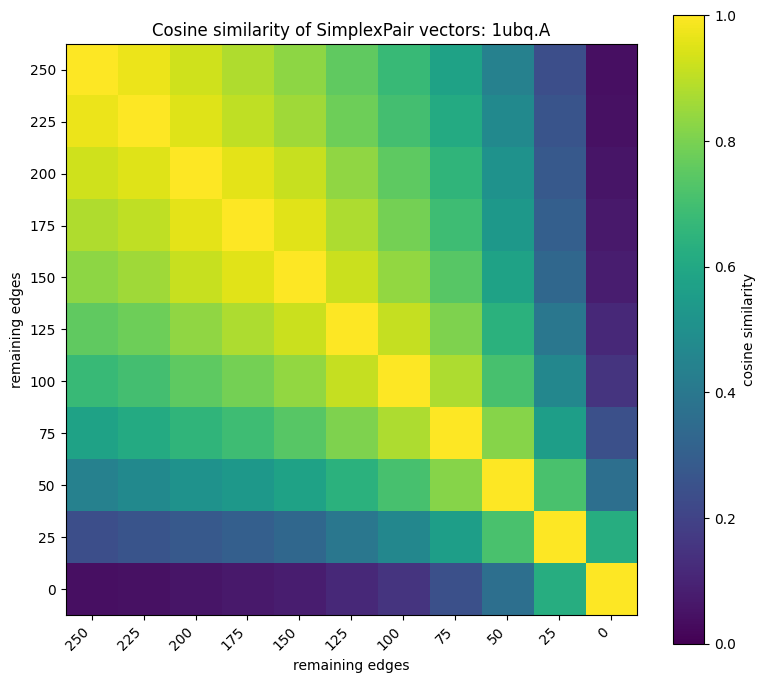

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(similarity_matrix, cmap="viridis", vmin=0.0, vmax=1.0, interpolation="nearest")

tick_step = max(1, len(sequence_summary) // 10)
tick_positions = list(range(0, len(sequence_summary), tick_step))
if tick_positions[-1] != len(sequence_summary) - 1:
    tick_positions.append(len(sequence_summary) - 1)
tick_labels = sequence_summary.loc[tick_positions, "edges"].astype(str).tolist()

ax.set_xticks(tick_positions)
ax.set_yticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha="right")
ax.set_yticklabels(tick_labels)
ax.set_xlabel("remaining edges")
ax.set_ylabel("remaining edges")
ax.set_title(f"Cosine similarity of SimplexPair vectors: {PDB_TOKEN}")
fig.colorbar(image, ax=ax, label="cosine similarity")
plt.tight_layout()
plt.show()
